## TIME SERIES FORECASTING PROJECT 

# Step 1: Data Collection and Exploration

In [1]:
# Step 1.1: Load the dataset into a Pandas DataFrame.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("airline_passengers.csv")

# First look at the data: top rows, shape and column types
print(df.head())
print("Shape:", df.shape)
print(df.dtypes)


     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121
Shape: (144, 2)
Month         object
Passengers     int64
dtype: object


In [2]:
# Step 1.2: Convert Month to proper dates and check the time range
df["Month"] = pd.to_datetime(df["Month"]) 
df = df.set_index("Month") 

# Check: full date range, any missing values, basic statistics
print("Date range:", df.index.min(), "to", df.index.max())
print("Missing values:\n", df.isnull().sum())
print(df.describe())

Date range: 1949-01-01 00:00:00 to 1960-12-01 00:00:00
Missing values:
 Passengers    0
dtype: int64
       Passengers
count  144.000000
mean   280.298611
std    119.966317
min    104.000000
25%    180.000000
50%    265.500000
75%    360.500000
max    622.000000


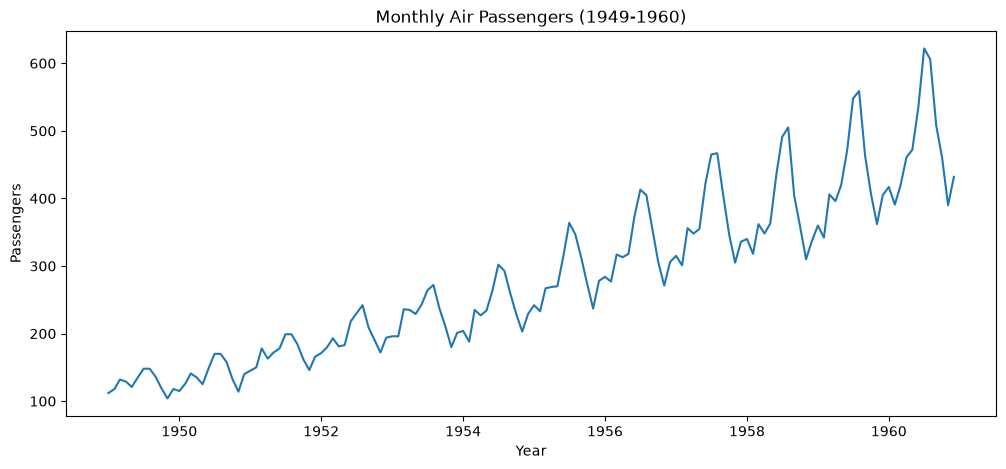

In [3]:
# Step 1.3: Plot the full series to see the overall trend
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["Passengers"])
plt.title("Monthly Air Passengers (1949-1960)")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.show()

# Step 2: Data Cleaning and Transformation

In [4]:
# Step 2.1: Ensuring there is exactly one row per month (regular frequency)
df = df.asfreq("MS")  # MS = month start; adds NaN for any missing months

# Check: did fixing the frequency reveal any gaps?
print("Missing values:\n", df.isnull().sum())
print("Rows:", len(df))

Missing values:
 Passengers    0
dtype: int64
Rows: 144


In [5]:
# Step 2.2: Create time-based features from the date index
df["Month_Num"] = df.index.month  # 1-12; helps the model learn yearly seasonality
df["Year"] = df.index.year  # helps the model learn the rising trend

print(df.head())
print("Shape:", df.shape)

            Passengers  Month_Num  Year
Month                                  
1949-01-01         112          1  1949
1949-02-01         118          2  1949
1949-03-01         132          3  1949
1949-04-01         129          4  1949
1949-05-01         121          5  1949
Shape: (144, 3)


In [6]:
# Step 2.3: Check for outliers using Z-score (|z| > 3 means outlier)
z_scores = (df["Passengers"] - df["Passengers"].mean()) / df["Passengers"].std()
outliers = df[z_scores.abs() > 3] # .abs will remove minus sign.

print("Outliers found:", len(outliers))
print(outliers)

Outliers found: 0
Empty DataFrame
Columns: [Passengers, Month_Num, Year]
Index: []


# Step 3: Exploratory Data Analysis

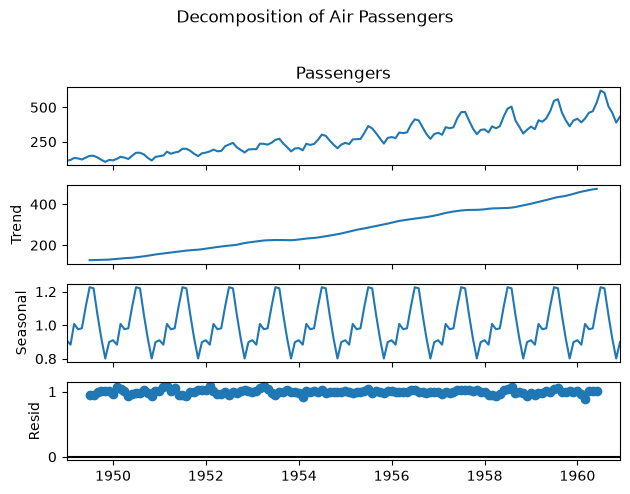

In [7]:
# Step 3.1: Split the series into trend, seasonality and leftover noise
from statsmodels.tsa.seasonal import seasonal_decompose

# multiplicative: yearly ups and downs grow bigger as passenger numbers grow
result = seasonal_decompose(df["Passengers"], model="multiplicative", period=12)

result.plot()
plt.suptitle("Decomposition of Air Passengers", y=1.02)
plt.tight_layout()
plt.show()


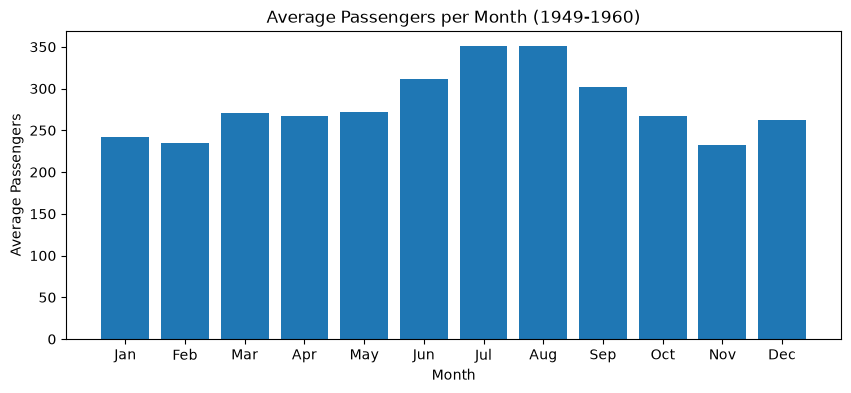

In [8]:
# Step 3.2: Average passengers for each calendar month (seasonality check)
monthly_avg = df.groupby("Month_Num")["Passengers"].mean()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 4))
plt.bar(monthly_avg.index, monthly_avg.values)
plt.title("Average Passengers per Month (1949-1960)")
plt.xlabel("Month")
plt.ylabel("Average Passengers")
plt.xticks(range(1, 13), month_names)
plt.show()


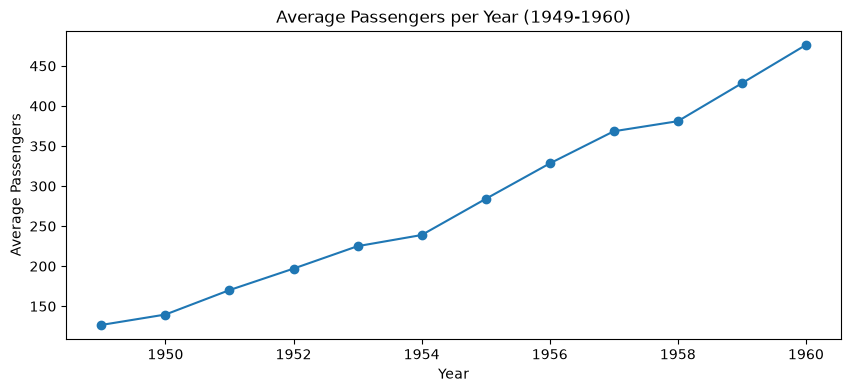

In [9]:
# Step 3.3: Average passengers per year (trend check)
yearly_avg = df.groupby("Year")["Passengers"].mean()

plt.figure(figsize=(10, 4))
plt.plot(yearly_avg.index, yearly_avg.values, marker="o")
plt.title("Average Passengers per Year (1949-1960)")
plt.xlabel("Year")
plt.ylabel("Average Passengers")
plt.show()

# Step 3.4: Key Findings
- The number of passengers rises every year — there is a clear upward trend.
- Every year follows the same wave: summer months are the busiest, winter months the quietest — strong yearly seasonality.
- No missing months and no outliers were found, so the data is clean.
- Because of the trend and seasonality, the model must learn from past months.

# Step 4: Model Development

In [10]:
# Step 4.1: Create lag features — past months become the input features
df["Lag_1"] = df["Passengers"].shift(1)    # passengers in the previous month
df["Lag_12"] = df["Passengers"].shift(12)  # passengers in the same month last year

df = df.dropna()  # first 12 rows have no lag values yet, so remove them
print(df.head(14))
print("Shape:", df.shape)

            Passengers  Month_Num  Year  Lag_1  Lag_12
Month                                                 
1950-01-01         115          1  1950  118.0   112.0
1950-02-01         126          2  1950  115.0   118.0
1950-03-01         141          3  1950  126.0   132.0
1950-04-01         135          4  1950  141.0   129.0
1950-05-01         125          5  1950  135.0   121.0
1950-06-01         149          6  1950  125.0   135.0
1950-07-01         170          7  1950  149.0   148.0
1950-08-01         170          8  1950  170.0   148.0
1950-09-01         158          9  1950  170.0   136.0
1950-10-01         133         10  1950  158.0   119.0
1950-11-01         114         11  1950  133.0   104.0
1950-12-01         140         12  1950  114.0   118.0
1951-01-01         145          1  1951  140.0   115.0
1951-02-01         150          2  1951  145.0   126.0
Shape: (132, 5)


In [11]:
# Step 4.2: Split by time — train on the past, test on the future (never shuffle!)
train = df[df.index < "1959"]   # 1950-1958: training data
test = df[df.index >= "1959"]   # 1959-1960: test data (the "future")

features = ["Lag_1", "Lag_12", "Month_Num", "Year"]
X_train, y_train = train[features], train["Passengers"]
X_test, y_test = test[features], test["Passengers"]

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (108, 4) | Test shape: (24, 4)


In [12]:
# Step 4.3: Train a Linear Regression model and check the error
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = LinearRegression()  # simple model, learns from past months
model.fit(X_train, y_train)  # train only on 1950-1958

# Predict the "future" (1959-1960) and measure how far off we are
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5

print("MAE:", round(mae, 2))   # average miss, in passengers
print("RMSE:", round(rmse, 2))  # like MAE but punishes big misses more

MAE: 15.17
RMSE: 18.45


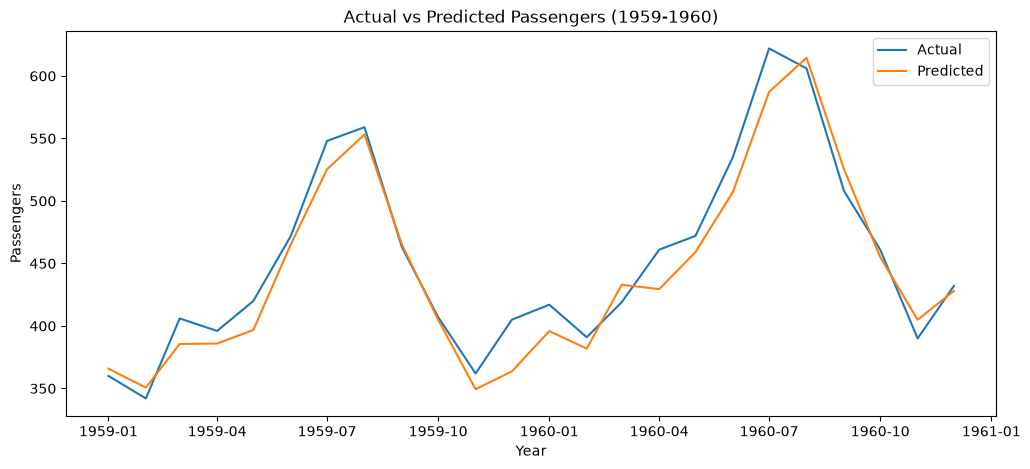

In [13]:
# Step 4.4: Plot actual vs predicted for the test years (1959-1960)
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test.values, label="Actual")
plt.plot(y_test.index, pred, label="Predicted")
plt.title("Actual vs Predicted Passengers (1959-1960)")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.legend()
plt.show()

# Step 5: Model Optimization

In [14]:
# Step 5.1: Trying Random Forest and compare with Linear Regression
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = mean_squared_error(y_test, rf_pred) ** 0.5

print("Linear Regression -> MAE:", round(mae, 2), "| RMSE:", round(rmse, 2))
print("Random Forest     -> MAE:", round(rf_mae, 2), "| RMSE:", round(rf_rmse, 2))

Linear Regression -> MAE: 15.17 | RMSE: 18.45
Random Forest     -> MAE: 34.73 | RMSE: 47.73


In [15]:
# Step 5.2: Training with Linear Regression on all data (1950-1960) and save it
import joblib

final_model = LinearRegression()
final_model.fit(df[features], df["Passengers"])

joblib.dump(final_model, "forecast_model.pkl")
print("Saved final model to forecast_model.pkl")

Saved final model to forecast_model.pkl
